# interpolation_station_grid 方法说明

将站点观测融合到规则格点。**推荐对外入口** `InterpSg(method=...)`，由 `method` 分派到各算法插件；各 `InterpSg*` 仍可单独调用。

| 插件 | 典型用途 |
| --- | --- |
| `InterpSg` | 统一入口：`method`=`idw` / `gaussian` / `kriging` / `cressman` |
| `InterpSgIdw` | 反距离权重；`reprocess=False` 绝对值+远点回退背景；`True` 偏差订正；可选高斯 |
| `InterpSgGaussian` | 最近邻 × 高斯；`reprocess=False` 绝对值+`d>halfR` 回退背景；`True` 偏差订正 |
| `InterpSgKriging` | 局部普通克里金；`reprocess=False` 绝对值（背景可只取网格）；`True` 偏差订正（无远点填充） |
| `InterpSgCressman` | Cressman：`reprocess=False` km 绝对值；`True` 创新量累加（须背景） |

接口统一为 `process(sta, grid=None, background=None)`（缺 `grid` 时可从 `background` 取网格；`reprocess=True` 须背景）。在包根或本 `nbs/` 目录打开即可运行（依赖 `meteva_base`，样例在 `resource/`）。


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
import pandas as pd
from meteva_base.tool.color_tools import (
    def_cmap_clevs,
    get_cmap_and_clevs_by_element_name,
)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_sg_cressman_plugin import InterpSgCressman
from interp_sg_gaussian_plugin import InterpSgGaussian
from interp_sg_idw_plugin import InterpSgIdw
from interp_sg_kriging import InterpSgKriging
from interp_sg_plugin import InterpSg


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. 原理

接口统一为 `process(sta, grid=None, background=None)`：`sta` 为站点表；`grid` 为目标网格信息；`background` 为格点场。均可缺 `grid` 时从 `background` 取网格；`reprocess=True` 时均须 `background`。

业务侧优先 `InterpSg(method=...)`；`method` 与 CLI `method=` 同值域（仅 `idw` / `gaussian` / `kriging` / `cressman`）。`reprocess` 与 `gaussian` 相互独立。

| 方法 | 原理 |
| --- | --- |
| **InterpSg** | 统一入口：按 `method` 构造并转调下列插件 |
| **InterpSgIdw** | 近邻反距离加权；`gaussian=True` 再乘高斯核。`reprocess=False`：插绝对值，超 `effectR` 回退背景；`True`：插 `obs−bg` 再叠回 |
| **InterpSgGaussian** | 每格点最近 1 站 × `exp(-(d/halfR)^2)`。`reprocess=False`：绝对值，超 `halfR` 回退背景；`True`：偏差订正 |
| **InterpSgKriging** | 局部普通克里金（无硬截断）。`reprocess=False`：绝对值（有背景时只取网格）；`True`：偏差订正 |
| **InterpSgCressman** | `reprocess=False`：km 绝对值加权（背景作初场）；`True`：在背景场上创新量累加（须背景） |

共同约定：按 `member`/`level`/`time`/`dtime` 切片后拼接；站点坐标转球面笛卡尔后用 KDTree 找近邻（距离为千米）；需对齐背景时用 `InterpGgLinear`（Cressman `reprocess=True` 直接在背景场上运算）。


## 2. 参数

`InterpSg` 构造参数已全部显式列出；按 `method` 选用，其余忽略。完整表见 `docs/interpolation_station_grid.md` §1.1。

| 参数 | 默认 | 适用 | 说明 |
| --- | --- | --- | --- |
| `method` | `idw` | 全部 | `idw` / `gaussian` / `kriging` / `cressman` |
| `reprocess` | `False` | 全部 | 绝对值 / 偏差路径，与 `gaussian` 独立 |
| `outer_value` | `None` | 全部 | 背景对齐越界填充 |
| `effectR` | `1000` | `idw` | 硬截断或高斯尺度（千米） |
| `nearNum` | `None` | idw / kriging / cressman | `None`→子插件默认 8/20/100 |
| `decrease` | `2` | `idw` | 衰减指数 |
| `gaussian` | `False` | `idw` | 是否乘高斯核；不随 `reprocess` 自动开启 |
| `halfR` | `20` | `gaussian` | 高斯半径（千米） |
| `model` / `sill` / `range_` / `nugget` | 见文档 | `kriging` | 变异函数 |
| `r_list` | 见文档 | `cressman` | 半径列表：`reprocess=False` 为千米，`True` 为度 |
| `rain_limit` / `degree_blend` 等 | 见文档 | `cressman` | 仅 `reprocess=True`：`rain_limit` 为降水回退阈值（`None` 不回退）；`degree_blend`∈[0,1]，默认 0.85，`1.0` 为纯度制；另有 `num_limit`、`smooth`、`power_param`、`r_km_scale`、`innov_gain`、`residual_*`、`station_anchor_*` |
| `sta` / `grid` / `background` | — | `process` | 站点、网格（可省）、背景（True 时必需） |

`effectR`、`halfR` 单位为千米，可写小数（如 `halfR=12.5`）。


## 3. 读入样例数据

- 站点：`resource/obs_gust_d24.csv`（`dtime=24` 的 `obs_gust`，已整理好 time/dtime）
- 背景场：`resource/bg_fcst_idw.nc`（由 `fcst_wind` IDW 得到，与 ShowDoc 示例同套）
- 目标网格：覆盖站点范围的 0.1° 经纬网；写出 `resource/target_grid.nc` 供 CLI 使用
- 有背景插值时以 `bg_fcst_idw.nc` 为背景

读入站点时若出现：

> 站点数据缺属性说明，已自动赋值默认值，使用需谨慎

来自 **`meb.read_stadata_from_csv`**：CSV 未带 meb 属性头时赋默认 attrs，属预期行为。

**插值输出图怎么看**

- 站点输入：`meb.scatter_sta`（`point_size` / `height` / `width`）
- 背景场：`pcolormesh_2d_grid`，不叠实况站
- 插值结果：`creat_axs` + `add_contourf` + `meb.add_scatter` 叠实况（同色标）
- 多方法对比：保留背景场子图；`loosen_row_gap` 拉大行距；每子图单独色标；结果子图 `add_scatter`


level,time,dtime,id,lon,lat,obs_gust

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
obs stations: 334
background: D:\workspace\test\00temp\interpolation_station_grid\resource\bg_fcst_idw.nc
target grid: 210 x 71
clevs = [ 1.6  3.4  5.5  8.  10.8 13.9 17.2 20.8 24.5 28.5 32.7]


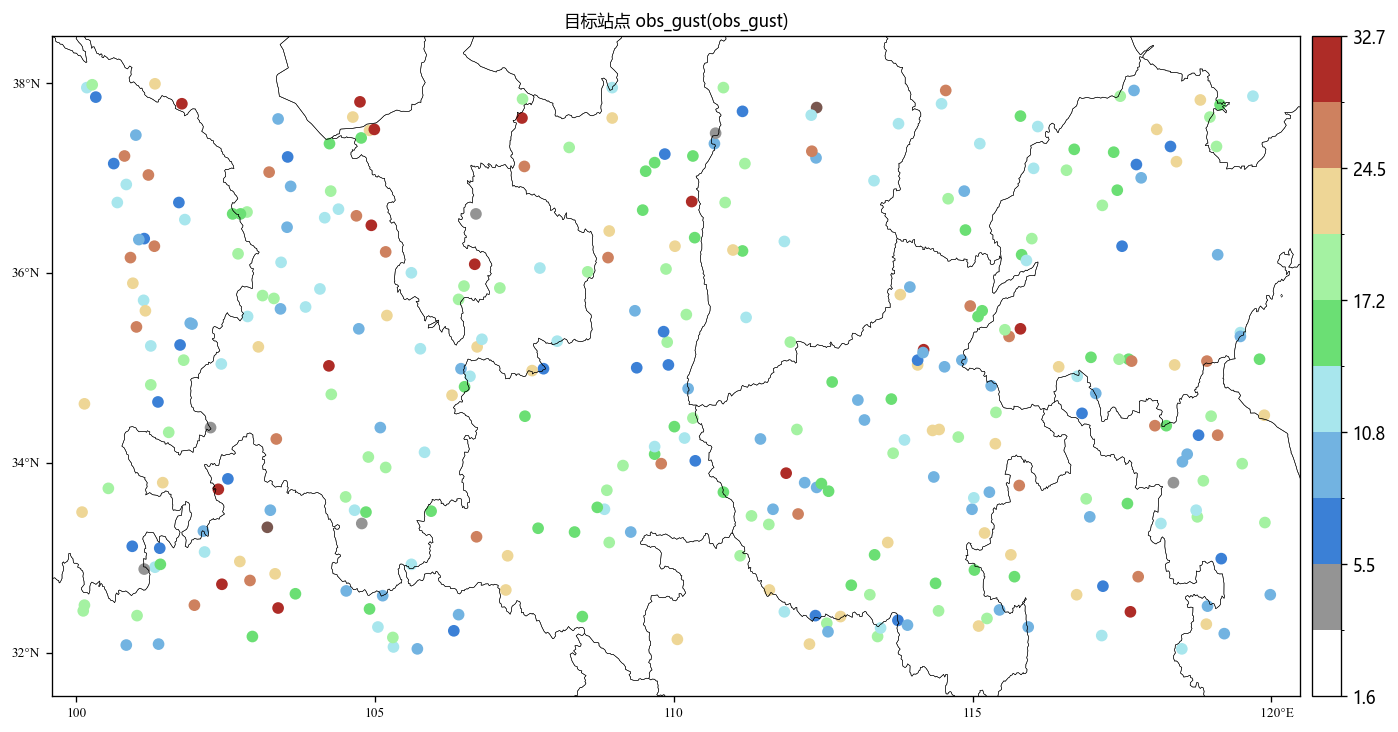

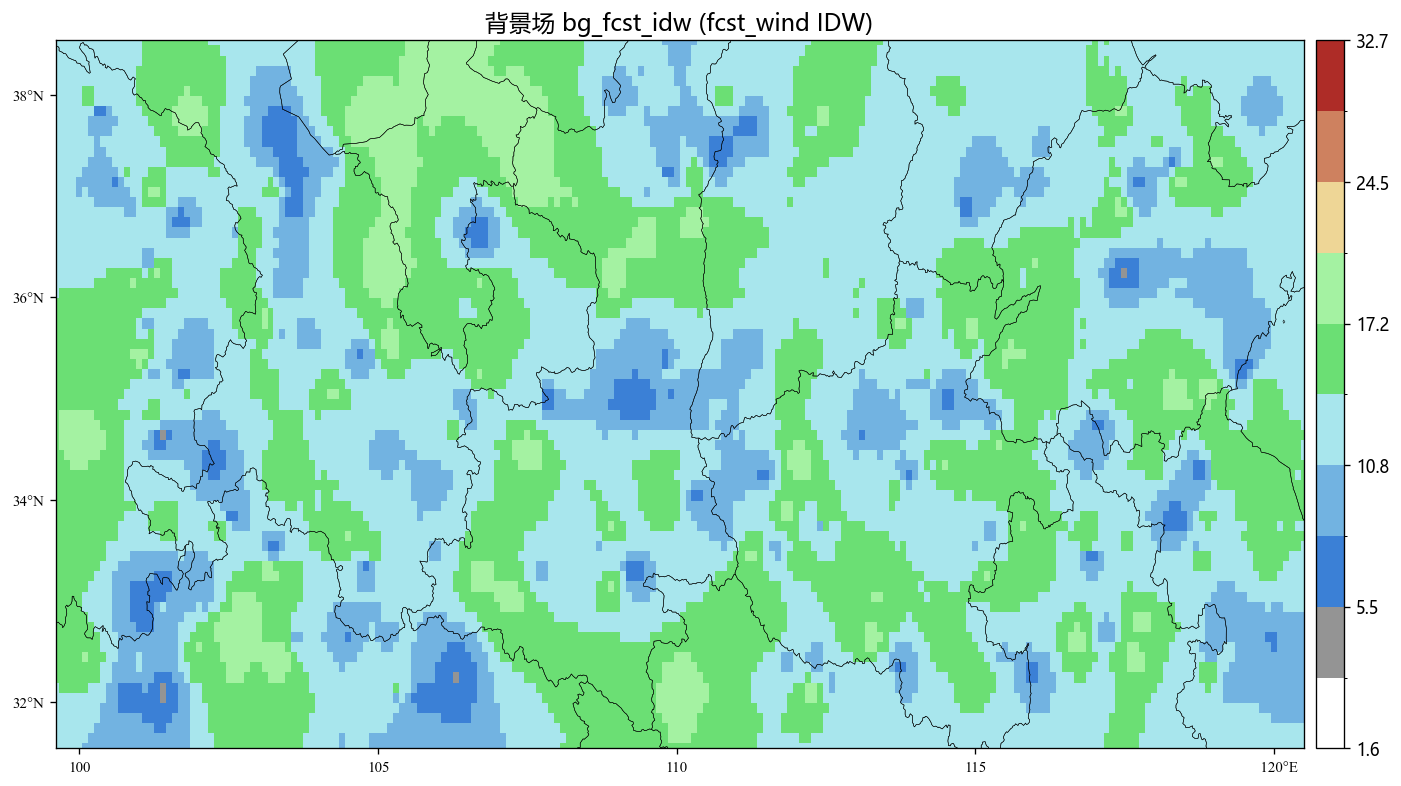

In [2]:
# 读已整理站点（obs_gust, dtime=24）与背景场
obs = meb.read_stadata_from_csv(str(DATA_DIR / "obs_gust_d24.csv"))
bg = meb.read_griddata_from_nc(str(DATA_DIR / "bg_fcst_idw.nc"))

lon0, lon1 = float(obs.lon.min()) - 0.5, float(obs.lon.max()) + 0.5
lat0, lat1 = float(obs.lat.min()) - 0.5, float(obs.lat.max()) + 0.5
tgt_grid = meb.basicdata.grid([lon0, lon1, 0.1], [lat0, lat1, 0.1])
MAP_EXTEND = [lon0, lon1, lat0, lat1]

# CLI 用目标空场（可重复写出）
meb.write_griddata_to_nc(meb.grid_data(tgt_grid), str(DATA_DIR / "target_grid.nc"), creat_dir=True)

print("obs stations:", len(obs))
print("background:", DATA_DIR / "bg_fcst_idw.nc")
print("target grid:", tgt_grid.nlon, "x", tgt_grid.nlat)

# wind_speed 色表按数据范围裁剪（对比图可再算）
cmap_all, clevs_all = get_cmap_and_clevs_by_element_name("wind_speed")
z = np.asarray(obs["obs_gust"], dtype=float)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP, CLEVS = def_cmap_clevs(cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True)
CLEVS = np.asarray(CLEVS, dtype=float)
if len(CLEVS) > 12:
    CLEVS = CLEVS[:: int(np.ceil((len(CLEVS) - 1) / 11))]
    CMAP, CLEVS = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS, vmin=CLEVS[0], vmax=CLEVS[-1], cut_colorbar=True
    )
    CLEVS = np.asarray(CLEVS, dtype=float)
print("clevs =", CLEVS)


def loosen_row_gap(axs, ncol, gap=0.07):
    """拉大 creat_axs 多行子图的行距，避免下行标题压住上行经度标签。"""
    n = len(axs)
    nrow = int(np.ceil(n / ncol))
    if nrow < 2:
        return
    for i, ax in enumerate(axs):
        r = i // ncol
        pos = ax.get_position()
        shrink = gap * 0.4
        new_h = max(pos.height - shrink, pos.height * 0.85)
        dy = ((nrow - 1) / 2 - r) * gap
        ax.set_position([pos.x0, pos.y0 + dy + shrink * 0.5, pos.width, new_h])


def plot_interp(grd, title, cmap=None, clevs=None, point_size=28):
    """插值结果单图：creat_axs + add_contourf + add_scatter 叠实况站。"""
    cmap = CMAP if cmap is None else cmap
    clevs = CLEVS if clevs is None else clevs
    axs = meb.creat_axs(
        1, MAP_EXTEND, ncol=1, height=6.5, width=12, dpi=120, title_list=[title]
    )
    meb.add_contourf(
        axs[0], grd, cmap=cmap, clevs=clevs, add_colorbar=True,
        title=title, title_fontsize=12,
    )
    # add_scatter 默认 title=None 会清空 add_contourf 标题，须显式传入
    meb.add_scatter(
        axs[0], obs, cmap=cmap, clevs=clevs,
        point_size=point_size, add_colorbar=False,
        title=title, title_fontsize=12,
    )
    plt.show()


# 输入示意：站点单独画；背景场不叠实况站
meb.scatter_sta(
    obs,
    title="目标站点 obs_gust",
    cmap=CMAP,
    clevs=CLEVS,
    map_extend=MAP_EXTEND,
    point_size=36,
    height=6.5,
    width=12,
    dpi=120,
    show=True,
)
meb.pcolormesh_2d_grid(
    bg,
    title="背景场 bg_fcst_idw (fcst_wind IDW)",
    cmap=CMAP,
    clevs=CLEVS,
    height=6.5,
    width=12,
    dpi=120,
    show=True,
)


## 4. 插件调用示例

### 4.0 InterpSg 统一入口（推荐）

同一份 `obs` / `tgt_grid`，用 `method` 切换算法；结果应与直接调用对应 `InterpSg*` 一致。


InterpSg(method=idw) (1, 1, 1, 1, 71, 210)
max|diff| = 0.0


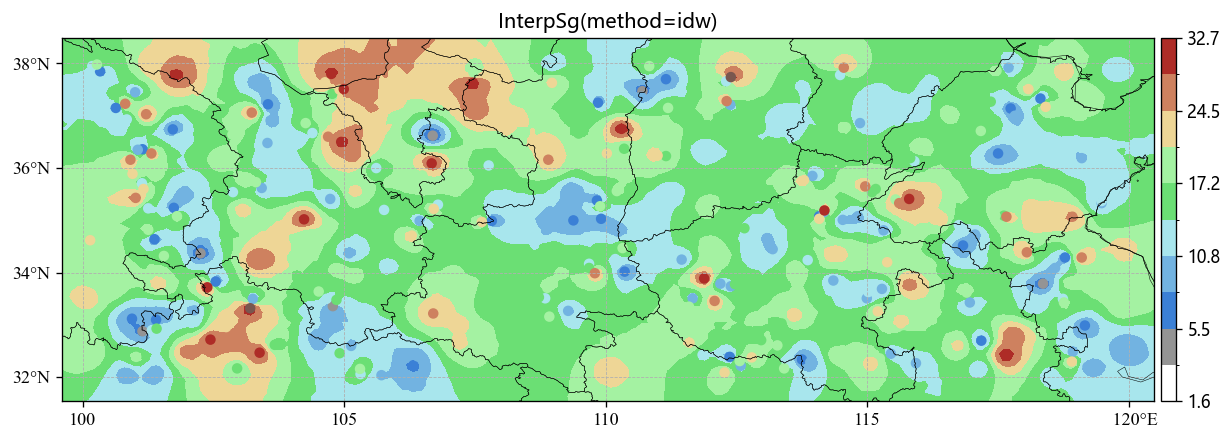

In [3]:
# 统一入口：method=idw，参数与下文 4.1 InterpSgIdw 示例对齐
grd_sg = InterpSg(
    method="idw", effectR=150, nearNum=8, decrease=2, reprocess=False
).process(obs, tgt_grid)
print("InterpSg(method=idw)", grd_sg.shape)

# 与直接插件对比（应完全一致）
grd_idw_ref = InterpSgIdw(
    effectR=150, nearNum=8, decrease=2, reprocess=False
).process(obs, tgt_grid)
print("max|diff| =", float(np.nanmax(np.abs(grd_sg.values - grd_idw_ref.values))))
plot_interp(grd_sg, "InterpSg(method=idw)")

### 4.1 InterpSgIdw（`reprocess=False`，无背景）

默认绝对值 IDW；无背景时超 `effectR` 填 0。也可写成 `InterpSg(method="idw", ...)`。

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[15.132091 , 14.435649 , 14.339102 , ..., 12.1301985,
            12.158875 , 12.193619 ],
           [15.381119 , 14.720163 , 14.633669 , ..., 12.032022 ,
            12.067951 , 12.1109   ],
           [15.670201 , 15.616135 , 14.995353 , ..., 11.919778 ,
            11.964888 , 12.018396 ],
           ...,
           [14.633559 , 14.67467  , 14.732019 , ..., 15.622587 ,
            15.742043 , 15.859599 ],
           [14.698105 , 15.361353 , 15.378199 , ..., 15.861113 ,
            15.93826  , 16.020248 ],
           [15.498287 , 15.507956 , 15.531102 , ..., 16.07618  ,
            16.121899 , 16.175762 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

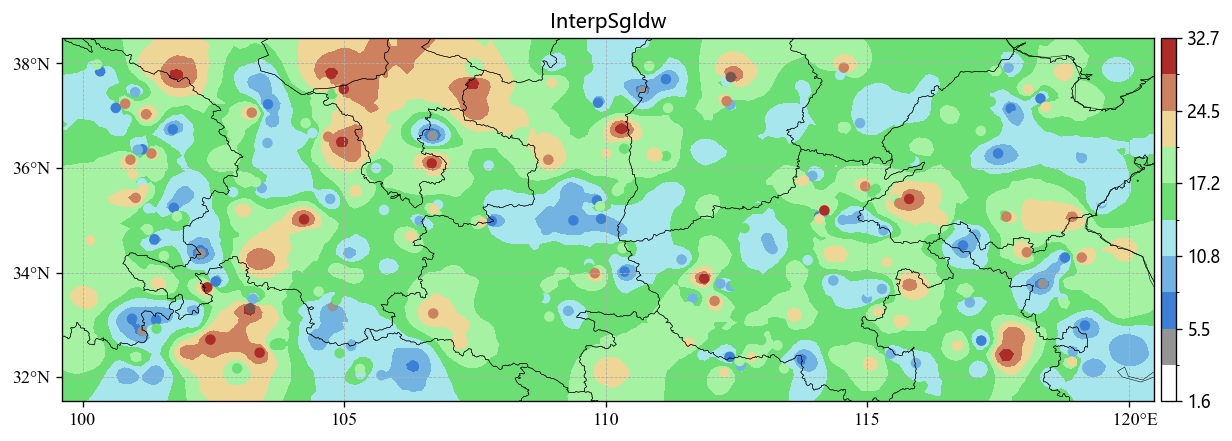

In [4]:
grd_idw = InterpSgIdw(
    effectR=150, nearNum=8, decrease=2, reprocess=False
).process(obs, tgt_grid)
print(grd_idw)
plot_interp(grd_idw, "InterpSgIdw")


### 4.2 InterpSgIdw（`gaussian=True`，`reprocess=False`）

`effectR` 作高斯半径；权重为 `1/d^decrease * exp(-(d/effectR)^2)`。仍为绝对值路径。


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           ...,
           [4.9204650e+00, 5.8698139e+00, 6.8312330e+00, ...,
            2.2336998e+00, 6.3485567e-14, 0.0000000e+00],
           [4.0391865e+00, 4.7900858e+00, 5.5305376e+00, ...,
            3.1742783e-14, 9.0218416e-28, 0.0000000e+00],
           [0.0000000e+00, 3.7437243e+00, 4.2973657e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4

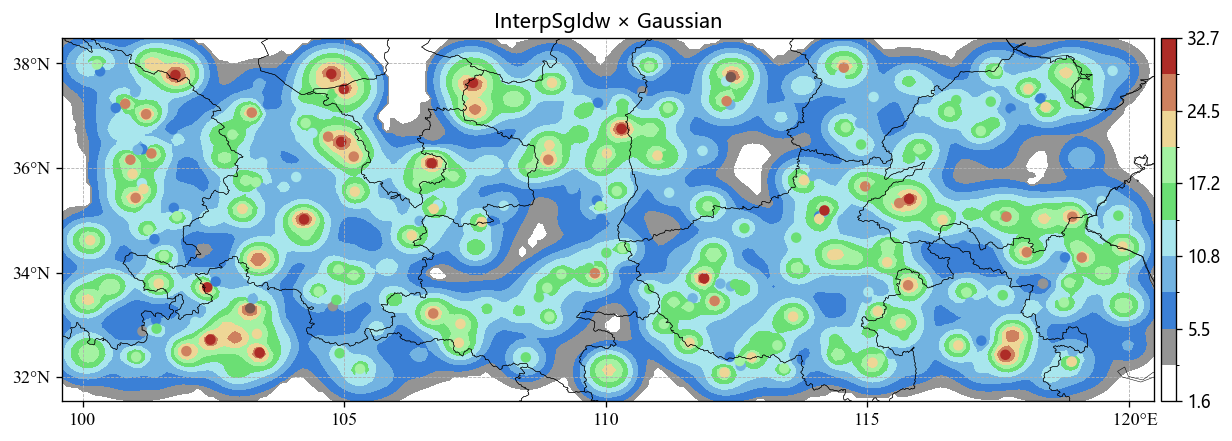

In [5]:
grd_idw_g = InterpSgIdw(
    effectR=80, nearNum=8, decrease=2, gaussian=True, reprocess=False
).process(obs, tgt_grid)
print(grd_idw_g)
plot_interp(grd_idw_g, "InterpSgIdw × Gaussian")


### 4.3 InterpSgGaussian（`reprocess=False`，无背景）

默认绝对值；无背景时 `d > halfR` 填 0。


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
           ...,
           [6.6121135e+00, 7.5049882e+00, 8.3172693e+00, ...,
            4.4828753e+00, 1.2741098e-13, 0.0000000e+00],
           [5.5813966e+00, 6.3339787e+00, 7.0185218e+00, ...,
            6.3705490e-14, 1.8106189e-27, 0.0000000e+00],
           [0.0000000e+00, 5.1430702e+00, 5.6980953e+00, ...,
            0.0000000e+00, 0.0000000e+00, 0.0000000e+00]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4

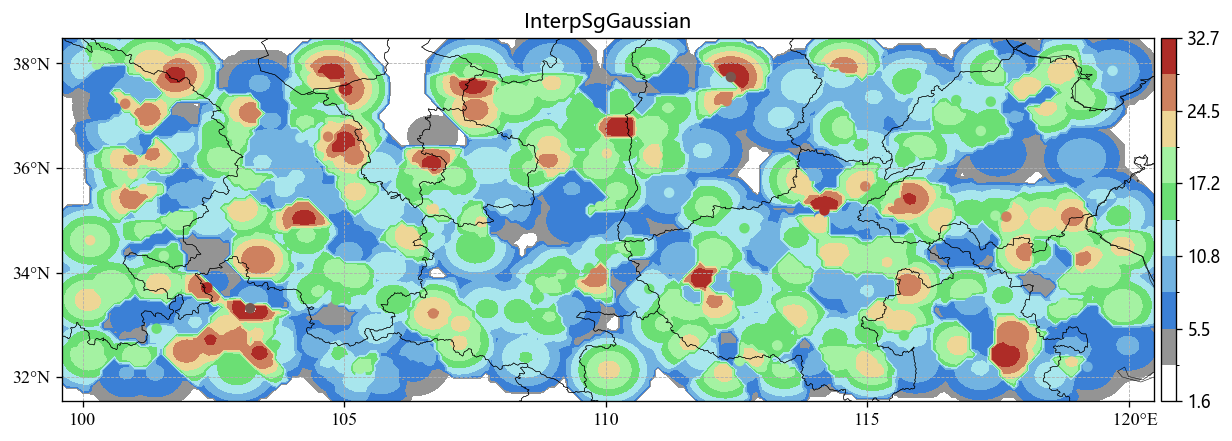

In [6]:
grd_gauss = InterpSgGaussian(halfR=80, reprocess=False).process(obs, tgt_grid)
print(grd_gauss)
plot_interp(grd_gauss, "InterpSgGaussian")


### 4.4 InterpSgKriging（`reprocess=False`，无背景）

默认绝对值；无硬截断，全场估计。须 `grid`（或有背景时只取网格）。


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[17.005768 , 16.501583 , 15.962619 , ..., 10.510852 ,
            10.85803  , 11.24303  ],
           [17.341656 , 16.835306 , 16.286818 , ..., 10.215047 ,
            10.58847  , 11.32726  ],
           [16.90556  , 17.241518 , 16.694263 , ...,  9.956402 ,
            10.626961 , 11.079279 ],
           ...,
           [16.014214 , 16.471975 , 16.467232 , ..., 10.5098295,
            10.361869 , 10.230801 ],
           [16.761734 , 16.43899  , 17.064661 , ..., 11.055417 ,
            10.390672 , 10.246423 ],
           [16.35297  , 16.908276 , 17.50143  , ..., 11.12132  ,
            10.99923  , 10.256142 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

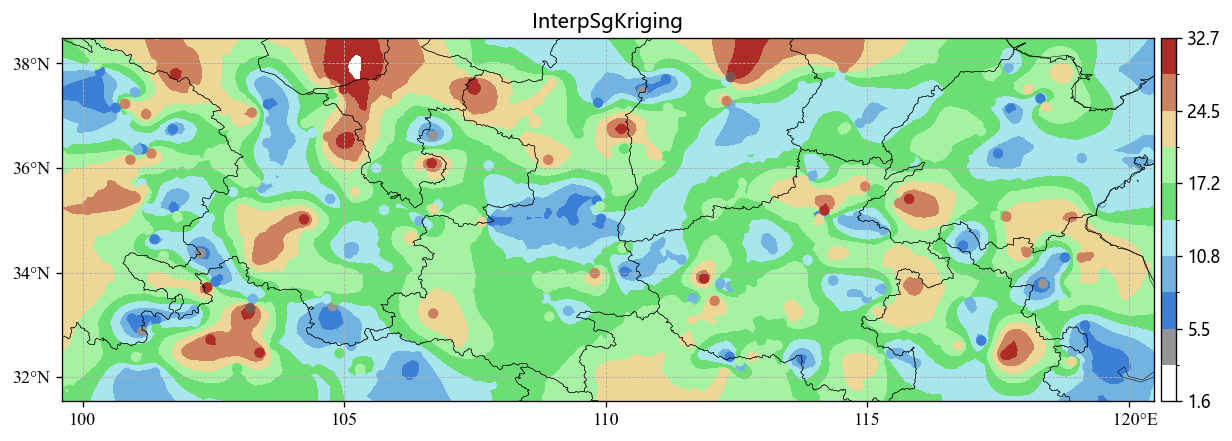

In [7]:
grd_krig = InterpSgKriging(
    model="spherical", nearNum=12, reprocess=False
).process(obs, tgt_grid)
print(grd_krig)
plot_interp(grd_krig, "InterpSgKriging")


### 4.5 InterpSgCressman（`reprocess=False`，无背景）

默认 km 核绝对值加权；无背景时从 0 场起扫。`r_list` 单位为千米。


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[16.288649, 16.010561, 15.646141, ..., 10.90591 ,
            10.719655, 10.401797],
           [16.360626, 20.52    , 20.52    , ..., 10.955915,
            10.736564, 10.454325],
           [20.297668, 20.033634, 19.95353 , ..., 11.163258,
            11.003584, 10.787138],
           ...,
           [14.620034, 14.472488, 14.380234, ..., 10.92    ,
            10.92    , 10.92    ],
           [15.060676, 14.785555, 14.629512, ..., 10.92    ,
            10.92    , 10.92    ],
           [16.15453 , 15.415541, 15.074766, ..., 10.92    ,
            10.92    , 15.339783]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 568B 31.54 31.64 31.74 31.84 

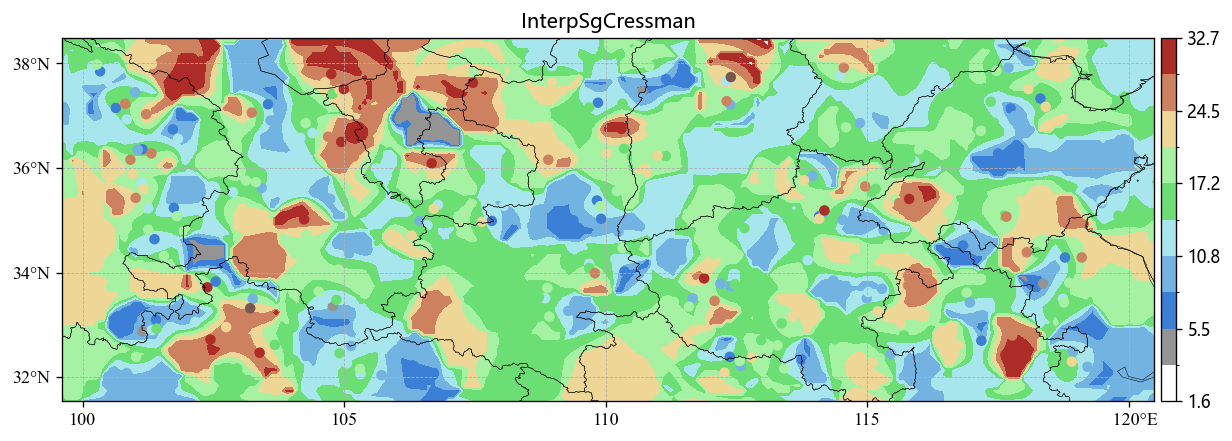

compare clevs = [ 1.6  3.4  5.5  8.  10.8 13.9 17.2 20.8 24.5 28.5 32.7]


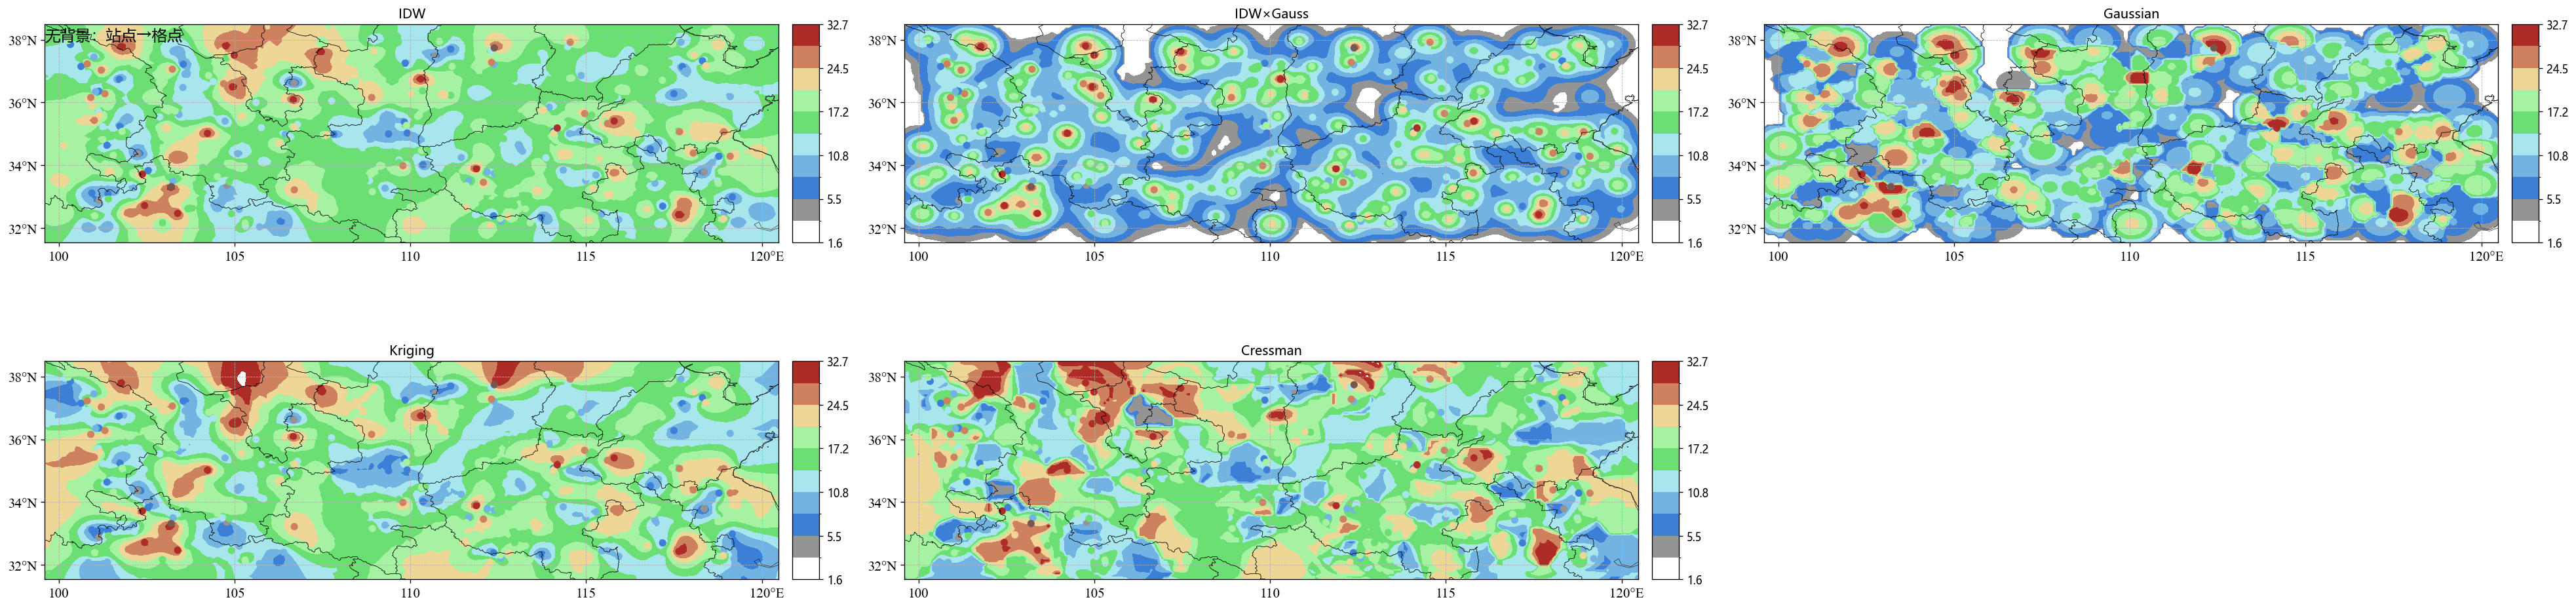

In [8]:
grd_cress = InterpSgCressman(
    r_list=[200, 100, 50], nearNum=40, reprocess=False
).process(obs, tgt_grid)
print(grd_cress)
plot_interp(grd_cress, "InterpSgCressman")

# 五方法对比：统一色阶；子图放大，实况点加大便于对照
nobg = {
    "IDW": grd_idw,
    "IDW×Gauss": grd_idw_g,
    "Gaussian": grd_gauss,
    "Kriging": grd_krig,
    "Cressman": grd_cress,
}
z = np.concatenate(
    [np.asarray(obs["obs_gust"], dtype=float).ravel()]
    + [np.asarray(g.values, dtype=float).ravel() for g in nobg.values()]
)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP, CLEVS = def_cmap_clevs(cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True)
CLEVS = np.asarray(CLEVS, dtype=float)
if len(CLEVS) > 12:
    CLEVS = CLEVS[:: int(np.ceil((len(CLEVS) - 1) / 11))]
    CMAP, CLEVS = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS, vmin=CLEVS[0], vmax=CLEVS[-1], cut_colorbar=True
    )
    CLEVS = np.asarray(CLEVS, dtype=float)
print("compare clevs =", CLEVS)

titles = list(nobg.keys())
n, ncol = len(titles), 3
axs = meb.creat_axs(
    n, MAP_EXTEND, ncol=ncol, width=11.5 * ncol, dpi=120,
    title_list=titles, wspace=1.6,
    sup_title="无背景：站点→格点", sup_fontsize=14,
)
loosen_row_gap(axs, ncol, gap=0.08)
for i, name in enumerate(titles):
    meb.add_contourf(
        axs[i], nobg[name], cmap=CMAP, clevs=CLEVS,
        add_colorbar=True, title=name, title_fontsize=12,
    )
    meb.add_scatter(
        axs[i], obs, cmap=CMAP, clevs=CLEVS, point_size=32, add_colorbar=False,
        title=name, title_fontsize=12,
    )
plt.show()


## 5. 带背景场的插值示例

本例使用 §3 的 `resource/bg_fcst_idw.nc`，对 `obs_gust` 调用：

- **`reprocess=False`（绝对值）**：IDW / Gaussian 超半径回退背景；Cressman 以背景为初场；Kriging 有背景时只取网格（场值会被全场覆盖，本例仍传 `grid`）
- **`reprocess=True`（偏差/创新量）**：须背景；IDW / Gaussian / Kriging 插 `obs−bg` 再叠回（可只传 `background`）；Cressman 在背景场上创新量累加（`r_list` 为度）


背景场                    min=5.20 max=19.94
IDW+bg(超半径回退背景场)       min=4.64 max=33.10
IDW+bg(偏差)             min=3.06 max=33.53
Gaussian+bg(超半径回退背景场)  min=1.72 max=33.49
Gaussian+bg(偏差)        min=2.91 max=35.51
Kriging+bg(偏差)         min=3.21 max=33.73
Cressman+bg(初值)        min=4.23 max=33.52
Cressman+bg(创新)        min=-2.23 max=45.97


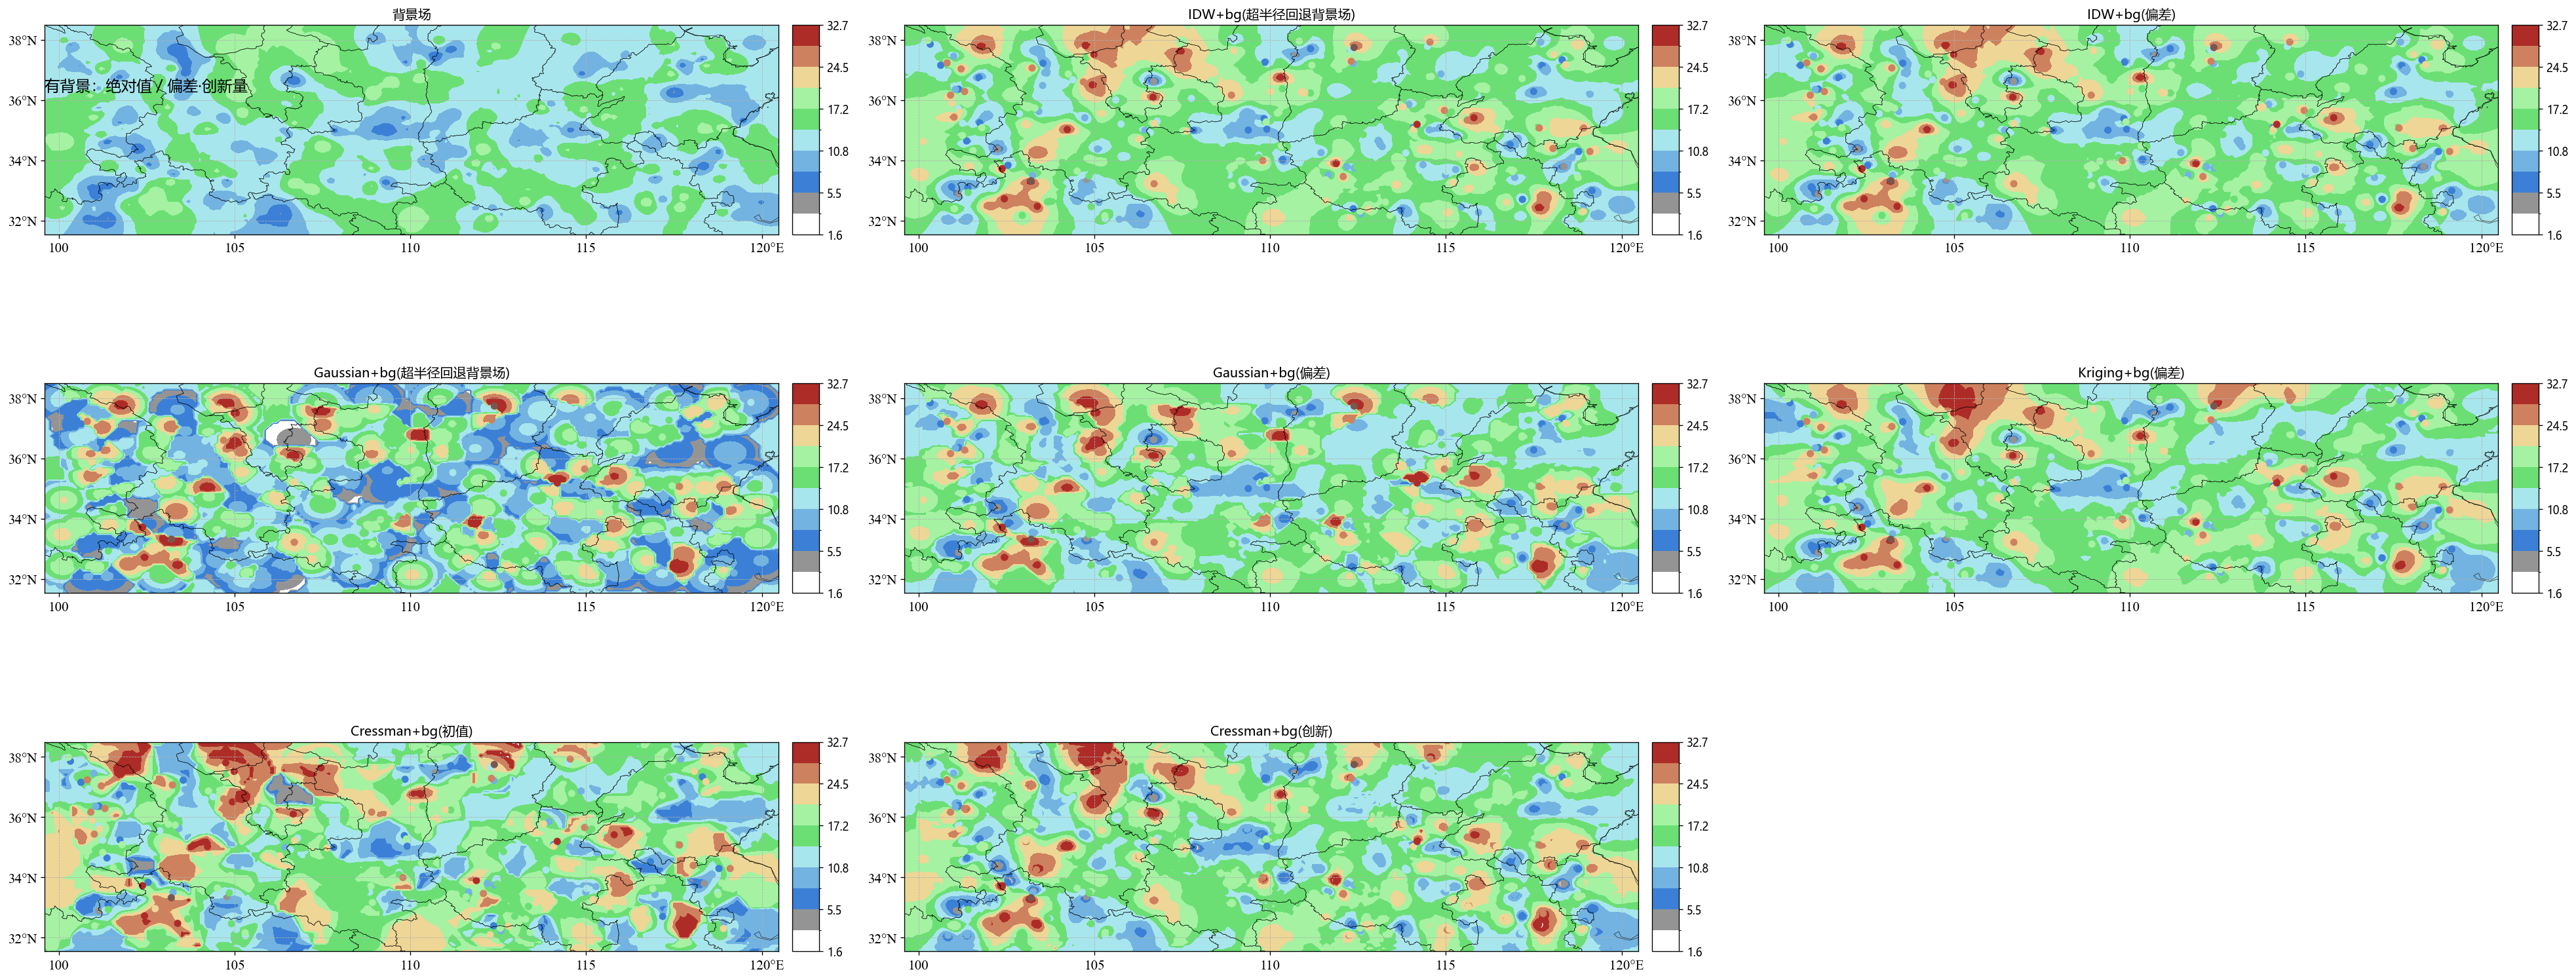

In [9]:
# 有背景对比：含背景场子图（不叠站）+ 各方法插值结果（add_scatter 叠实况）
with_bg = {
    "背景场": bg,
    "IDW+bg(超半径回退背景场)": InterpSgIdw(
        effectR=150, nearNum=8, decrease=2, outer_value=0.0, reprocess=False
    ).process(obs, tgt_grid, background=bg),
    "IDW+bg(偏差)": InterpSgIdw(
        effectR=150, nearNum=8, decrease=2, outer_value=0.0, reprocess=True
    ).process(obs, background=bg),
    "Gaussian+bg(超半径回退背景场)": InterpSgGaussian(
        halfR=80, outer_value=0.0, reprocess=False
    ).process(obs, tgt_grid, background=bg),
    "Gaussian+bg(偏差)": InterpSgGaussian(
        halfR=80, outer_value=0.0, reprocess=True
    ).process(obs, background=bg),
    "Kriging+bg(偏差)": InterpSgKriging(
        model="spherical", nearNum=12, outer_value=0.0, reprocess=True
    ).process(obs, background=bg),
    "Cressman+bg(初值)": InterpSgCressman(
        r_list=[200, 100, 50], nearNum=40, outer_value=0.0, reprocess=False
    ).process(obs, tgt_grid, background=bg),
    "Cressman+bg(创新)": InterpSgCressman(
        r_list=[1.0, 0.8, 0.6, 0.4], nearNum=40, reprocess=True
    ).process(obs, background=bg),
}

for k, da in with_bg.items():
    z = np.asarray(da.values, dtype=float)
    print(f"{k:22s} min={np.nanmin(z):.2f} max={np.nanmax(z):.2f}")

z = np.concatenate(
    [np.asarray(obs["obs_gust"], dtype=float).ravel()]
    + [np.asarray(g.values, dtype=float).ravel() for g in with_bg.values()]
)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP_BG, CLEVS_BG = def_cmap_clevs(
    cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True
)
CLEVS_BG = np.asarray(CLEVS_BG, dtype=float)
if len(CLEVS_BG) > 12:
    CLEVS_BG = CLEVS_BG[:: int(np.ceil((len(CLEVS_BG) - 1) / 11))]
    CMAP_BG, CLEVS_BG = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS_BG, vmin=CLEVS_BG[0], vmax=CLEVS_BG[-1], cut_colorbar=True
    )
    CLEVS_BG = np.asarray(CLEVS_BG, dtype=float)

titles = list(with_bg.keys())
n, ncol = len(titles), 3
axs = meb.creat_axs(
    n, MAP_EXTEND, ncol=ncol, width=11.5 * ncol, dpi=120,
    title_list=titles, wspace=1.6,
    sup_title="有背景：绝对值 / 偏差·创新量", sup_fontsize=14,
)
loosen_row_gap(axs, ncol, gap=0.08)
for i, name in enumerate(titles):
    meb.add_contourf(
        axs[i], with_bg[name], cmap=CMAP_BG, clevs=CLEVS_BG,
        add_colorbar=True, title=name, title_fontsize=12,
    )
    if name != "背景场":
        meb.add_scatter(
            axs[i], obs, cmap=CMAP_BG, clevs=CLEVS_BG,
            point_size=32, add_colorbar=False,
            title=name, title_fontsize=12,
        )
plt.show()


## 6. CLI 使用示例

在 `00temp` 目录等价于：

```bash
python -m interpolation_station_grid method=idw sta=resource/obs_gust_d24.csv grid=resource/target_grid.nc output=resource/cli_idw_out.nc idw_effect_r=150 idw_near_num=8 idw_decrease=2
```

下面用 Python 调用 `process`（与命令行同名参数），输出写到 `resource/`。


level,time,dtime,id,lon,lat,obs_gust

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
写出 → D:\workspace\test\00temp\interpolation_station_grid\resource\cli_idw_out.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[15.132091 , 14.435649 , 14.339102 , ..., 12.1301985,
            12.158875 , 12.193619 ],
           [15.381119 , 14.720163 , 14.633669 , ..., 12.032022 ,
            12.067951 , 12.1109   ],
           [15.670201 , 15.616135 , 14.995353 , ..., 11.919778 ,
            11.964888 , 12.018396 ],
           ...,
           [14.633559 , 14.67467  , 14.732019 , ..., 15.622587 ,
            15.742043 , 15.859599 ],
           [14.698105 , 15.361353 , 15.378199 , ..., 15.861113 ,
            15.93826  , 16.020248 ],
           [15.498287 , 15.507956 , 15.531102 , ..., 16.07618  ,
            16.121899 , 16.175762 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_

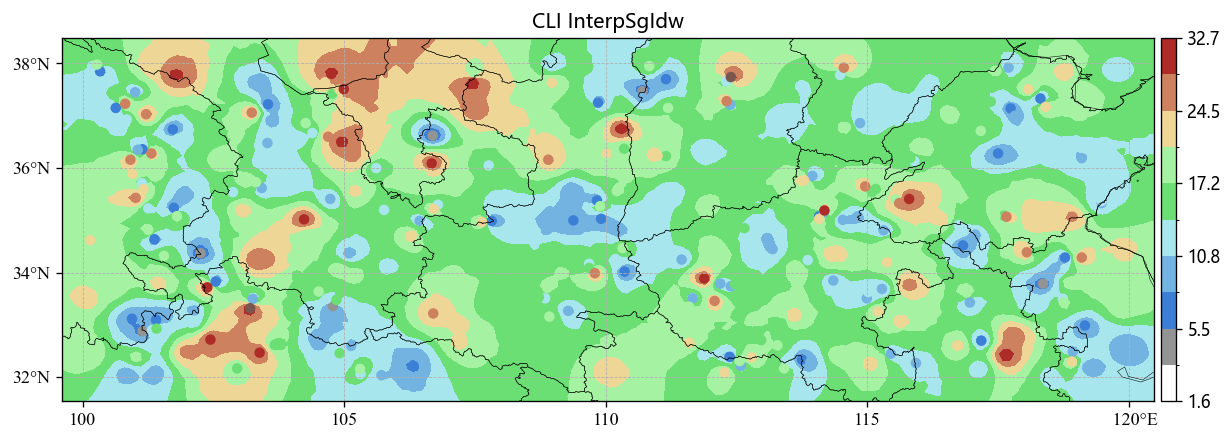

In [10]:
from cli.interpolation_station_grid_cli import process

out_nc = str(DATA_DIR / "cli_idw_out.nc")
grd_cli = process(
    method="idw",
    sta=str(DATA_DIR / "obs_gust_d24.csv"),
    grid=str(DATA_DIR / "target_grid.nc"),
    output=out_nc,
    idw_effect_r=150,
    idw_near_num=8,
    idw_decrease=2,
    sta_type="csv",
    grid_type="nc",
    output_type="nc",
)
print("output =", out_nc)
print(grd_cli)
plot_interp(grd_cli, "CLI InterpSgIdw")


## 7. 小结

- **推荐对外入口**：`InterpSg(method=...)`；`method` 与 CLI `method=` 同值域；各 `InterpSg*` 仍可单独调用。
- 插件接口统一：`process(sta, grid=None, background=None)`；缺 `grid` 时可从 `background` 取网格。
- `reprocess=False`：绝对值路径（IDW/Gaussian 超半径回退背景；Cressman 背景作初场；Kriging 无远点填充，背景可只取网格）。
- `reprocess=True`：须背景；权重仍由 `gaussian` 决定（默认 false）。
- 样例：`resource/obs_gust_d24.csv` + `resource/target_grid.nc`；背景场 `resource/bg_fcst_idw.nc`。
- 半径 `effectR` / `halfR` / `idw_effect_r` / `gaussian_half_r` 均为千米，可写小数。
- CLI：`python -m interpolation_station_grid method=idw|gaussian|kriging|cressman`（在 `00temp` 目录执行，内部走 `InterpSg`）；`grid` 与 `background` 至少其一；Cressman 度制路径的高级参数用 `cressman_degree_blend`、`cressman_rain_limit` 等键传入（仅 `cressman` + `reprocess=true` 生效）。
- 选型：平滑分析常用 IDW / Gaussian；空间相关结构更复杂时试 Kriging；有较好背景场时用 `reprocess=True` 做偏差/创新量订正。
